<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture attribution](README.md)

# 01 · Keep unlabeled events when summarizing an EVTX timeline

An event log can parse successfully while most of its event identifiers are absent from a small reference table. An inner join would quietly remove those records. We will inspect input diagnostics, materialize the bundled public Security-log sample, retain every parsed record through a left join, and see how a wider time bin changes the summary.

The input is a **seven-record public test corpus**, recorded in 2016, not a live collection or a representative host history. It is a real EVTX file, not a synthesized timeline. There is no inference of compromise, normality, event rates on a production host or collection completeness.

## Choose a display bin width

`BIN_SECONDS` is either **10** or **30** seconds. Bins are aligned to the Unix epoch in UTC and use **[start, end)** boundaries: an event exactly on an endpoint belongs to the following bin. Only the bins spanning the first through last parsed event are shown.

Change only **10 → 30 seconds** at the end. Predict fewer displayed bins while the parsed-record total, event types and reference coverage remain unchanged. Restart the kernel and Run All after editing.

In [1]:
BIN_SECONDS = 10  # Accepted: 10 or 30 seconds; experiment: 30

In [2]:
import hashlib
import os
from datetime import datetime, timezone
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert BIN_SECONDS in {10,30} and type(BIN_SECONDS) is int
fixture=Path("fixtures/sample-security.evtx")
fixture_hash=hashlib.sha256(fixture.read_bytes()).hexdigest()
assert fixture_hash=="50c87926d2dfed9776906ffbcc77e61577940910a71fb1c1871860a4e2213456", "Fixture bytes differ from the documented public sample."
assert not Path("fixtures/intentionally-absent.evtx").exists()
os.environ["PLOOMBER_STATS_ENABLED"]="false"
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,"Source: public evtx crate Security sample · 2016-06-29 UTC · selected test records, not a complete host timeline",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.06,1,.98));plt.show()
con=haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-evtx/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-evtx/notebooks/pyproject.toml.

## Attach the published parser and distinguish input states

The literal native release is downloaded, checksum-verified and cached by VGI. Once installed, the worker parses local bytes without a network service. The notebook reads only its bundled fixture; it does not search for local Windows logs.

The diagnostic examples include the real fixture, deliberate non-EVTX bytes, a deliberately absent path and SQL NULL. A zero count for malformed bytes is not evidence of an empty valid log. An unreadable path and a NULL input both yield NULL scalar diagnostics here. `is_valid_evtx` checks header/parser construction; it does not guarantee every record is intact, authentic or complete.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'evtx' AS evtx (
    TYPE vgi,
    LOCATION 'github-auto://Query-farm/vgi-evtx@v0.4.0'
);

,Success


In [4]:
%%sql input_checks <<
SELECT 'Public fixture' AS input_case,
       evtx.main.is_valid_evtx('fixtures/sample-security.evtx') AS parser_constructs,
       evtx.main.evtx_record_count('fixtures/sample-security.evtx') AS parsed_records
UNION ALL
SELECT 'Deliberate non-EVTX bytes',evtx.main.is_valid_evtx('not an evtx file'::BLOB),evtx.main.evtx_record_count('not an evtx file'::BLOB)
UNION ALL
SELECT 'Absent path',evtx.main.is_valid_evtx('fixtures/intentionally-absent.evtx'),evtx.main.evtx_record_count('fixtures/intentionally-absent.evtx')
UNION ALL
SELECT 'SQL NULL',evtx.main.is_valid_evtx(NULL::BLOB),evtx.main.evtx_record_count(NULL::BLOB);

In [5]:
display(input_checks)
checks=input_checks.set_index("input_case")
assert bool(checks.loc["Public fixture","parser_constructs"])
assert checks.loc["Public fixture","parsed_records"]>0
assert not bool(checks.loc["Deliberate non-EVTX bytes","parser_constructs"])
assert checks.loc["Deliberate non-EVTX bytes","parsed_records"]==0
assert checks.loc[["Absent path","SQL NULL"],["parser_constructs","parsed_records"]].isna().all().all()
prose(f"Fixture SHA-256: `{fixture_hash}`. **{fixture.stat().st_size:,} bytes** are verified against the copied public corpus. The malformed-byte diagnostic is an explicitly constructed negative control, separate from the real event data.")

,input_case,parser_constructs,parsed_records
0,Public fixture,True,7
1,Deliberate non-EVTX bytes,False,0
2,Absent path,<NA>,<NA>
3,SQL NULL,<NA>,<NA>


Fixture SHA-256: `50c87926d2dfed9776906ffbcc77e61577940910a71fb1c1871860a4e2213456`. **69,632 bytes** are verified against the copied public corpus. The malformed-byte diagnostic is an explicitly constructed negative control, separate from the real event data.

## Parse once, retaining the complete normalized event JSON

The table function takes a constant local path. We retain its full output in an in-memory table and display only timing, event identifiers and classification metadata. The parser can skip individual malformed records, so a count of returned rows is a count of **successfully parsed records**, not proof of complete acquisition.

`time_created` comes from the EVTX record header's UTC timestamp, but the SQL column is a timezone-free TIMESTAMP. We label it UTC by this documented worker contract; we do not reinterpret it in the notebook machine's local timezone. Record IDs are file-scoped identifiers, not a global join key across hosts or files.

In [6]:
%%sql
CREATE TABLE parsed_events AS
SELECT * FROM evtx.main.evtx_records('fixtures/sample-security.evtx');
CREATE TABLE event_reference AS
SELECT * FROM evtx.main.windows_event_id_reference;

,Count


In [7]:
%%sql diagnostics <<
SELECT count(*) AS parsed_records,count(DISTINCT record_id) AS distinct_record_ids,
       min(time_created) AS first_utc,max(time_created) AS last_utc,
       count(*) FILTER (WHERE time_created IS NULL) AS missing_times,
       count(*) FILTER (WHERE event_id IS NULL OR channel IS NULL) AS missing_reference_keys,
       count(DISTINCT provider) AS providers,count(DISTINCT channel) AS channels
FROM parsed_events;

In [8]:
display(diagnostics)
d=diagnostics.iloc[0]
assert d.parsed_records==checks.loc["Public fixture","parsed_records"]
assert d.parsed_records==d.distinct_record_ids and d.missing_times==0
assert con.execute("SELECT count(*) FROM (SELECT event_id,channel,count(*) n FROM event_reference GROUP BY ALL HAVING n>1)").fetchone()[0]==0
providers=con.execute("SELECT DISTINCT provider,channel FROM parsed_events").fetchall()
assert providers==[("Microsoft-Windows-Security-Auditing","Security")], "This reference join is scoped to the sample's provider/channel; review other providers before reuse."
prose(f"The sample contains **{int(d.parsed_records)} parsed records** over **{(d.last_utc-d.first_utc).total_seconds():.3f} seconds**, "
      f"from **{d.first_utc} UTC** through **{d.last_utc} UTC**. Scalar count and table count agree; this checks internal consistency, not the completeness of the original host log.")

,parsed_records,distinct_record_ids,first_utc,last_utc,missing_times,missing_reference_keys,providers,channels
0,7,7,2016-06-29 15:24:34.346,2016-06-29 15:25:08.822,0,0,1,1


The sample contains **7 parsed records** over **34.476 seconds**, from **2016-06-29 15:24:34.346000 UTC** through **2016-06-29 15:25:08.822000 UTC**. Scalar count and table count agree; this checks internal consistency, not the completeness of the original host log.

## Left join on event ID and channel; preserve missing meanings

The worker's reference is a small convenience table, not the full Windows event catalog. We first verify its join keys are unique so a join cannot multiply event rows. This file's provider is checked explicitly: an event number alone is not a universal meaning across providers.

A reference name of **Failed logon** for Security event 4625 agrees with [Microsoft's event documentation](https://learn.microsoft.com/en-us/windows/security/threat-protection/auditing/event-4625). That label alone does not establish an attack. NULL meanings stay **Not in this reference**, not “benign” or “unknown Windows event.”

In [9]:
%%sql
CREATE TABLE labeled_events AS
SELECT p.record_id,p.time_created,p.event_id,p.channel,p.provider,p.level,
       r.name AS reference_name,
       CASE WHEN r.name IS NULL THEN 'Not in this reference' ELSE 'Reference label available' END AS label_status
FROM parsed_events p LEFT JOIN event_reference r USING(event_id,channel);

,Count


In [10]:
%%sql timeline <<
SELECT record_id,time_created AS record_time_utc,event_id,channel,level,reference_name,label_status
FROM labeled_events ORDER BY time_created,record_id;

In [11]:
%%sql coverage <<
SELECT label_status,count(*) AS records,count(DISTINCT event_id) AS event_types
FROM labeled_events GROUP BY label_status ORDER BY label_status;

,record_id,record_time_utc,event_id,channel,level,reference_name,label_status
0,1,2016-06-29 15:24:34.346000,5152,Security,0,None,Not in this reference
1,2,2016-06-29 15:24:36.686000,4611,Security,0,None,Not in this reference
2,3,2016-06-29 15:24:36.686000,4776,Security,0,None,Not in this reference
3,4,2016-06-29 15:24:36.717200,4625,Security,0,Failed logon,Reference label available
4,5,2016-06-29 15:24:57.090800,5152,Security,0,None,Not in this reference
5,6,2016-06-29 15:25:08.822000,5157,Security,0,None,Not in this reference
6,7,2016-06-29 15:25:08.822000,4673,Security,0,None,Not in this reference


,label_status,records,event_types
0,Not in this reference,6,5
1,Reference label available,1,1


The reference labels **1 of 7 records**; **6** remain in the timeline with no reference name. An inner join would retain only the labeled subset. The displayed Level values are not used as a severity score or a compromise decision.

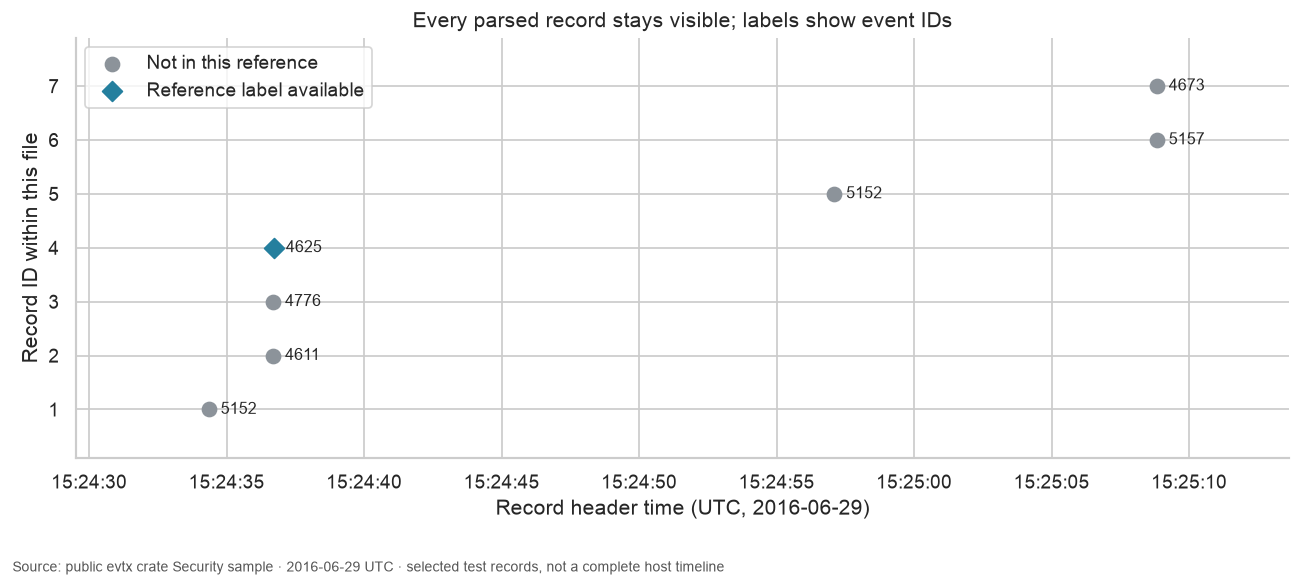

In [12]:
display(timeline)
display(coverage)
assert len(timeline)==int(d.parsed_records) and timeline.record_id.is_unique
assert coverage.records.sum()==len(timeline)
known=int(timeline.reference_name.notna().sum())
prose(f"The reference labels **{known} of {len(timeline)} records**; **{len(timeline)-known}** remain in the timeline with no reference name. "
      "An inner join would retain only the labeled subset. The displayed Level values are not used as a severity score or a compromise decision.")
fig,ax=plt.subplots(figsize=(10.5,4.8))
for status,color,marker in [("Not in this reference","#8c939a","o"),("Reference label available","#247f9e","D")]:
    rows=timeline[timeline.label_status.eq(status)]
    ax.scatter(rows.record_time_utc,rows.record_id,color=color,marker=marker,s=65,label=status)
for r in timeline.itertuples():ax.annotate(str(r.event_id),(r.record_time_utc,r.record_id),xytext=(7,0),textcoords="offset points",va="center",fontsize=9)
ax.set(xlabel="Record header time (UTC, 2016-06-29)",ylabel="Record ID within this file",title="Every parsed record stays visible; labels show event IDs")
ax.yaxis.set_major_locator(MaxNLocator(integer=True));ax.margins(x=.14,y=.15)
ax.legend(loc="upper left");finish(fig)

## Count records in explicit half-open bins

We floor epoch seconds to the selected width, then generate every bin between the first and last event bins. The left join fills a count of zero only where the materialized sample has no parsed events in that interval. It does not claim that a real host produced no events.

Reference coverage remains separate within each bar. Counts per bin depend on width and alignment; comparing them as if they were a rate would change the meaning.

In [13]:
%%sql bins <<
WITH assigned AS (
  SELECT *,CAST(floor(epoch(time_created)/{{BIN_SECONDS}})*{{BIN_SECONDS}} AS BIGINT) AS bin_epoch
  FROM labeled_events
), limits AS (
  SELECT min(bin_epoch) AS first_bin,max(bin_epoch) AS last_bin FROM assigned
), grid AS (
  SELECT unnest(generate_series(first_bin,last_bin,{{BIN_SECONDS}})) AS bin_epoch FROM limits
)
SELECT CAST(to_timestamp(g.bin_epoch) AT TIME ZONE 'UTC' AS TIMESTAMP) AS bin_start_utc,
       CAST(to_timestamp(g.bin_epoch+{{BIN_SECONDS}}) AT TIME ZONE 'UTC' AS TIMESTAMP) AS bin_end_utc,
       count(a.record_id) AS parsed_records,
       count(a.record_id) FILTER (WHERE a.reference_name IS NOT NULL) AS labeled_records,
       count(a.record_id) FILTER (WHERE a.reference_name IS NULL) AS unlabeled_records
FROM grid g LEFT JOIN assigned a USING(bin_epoch)
GROUP BY g.bin_epoch ORDER BY g.bin_epoch;

,bin_start_utc,bin_end_utc,parsed_records,labeled_records,unlabeled_records
0,2016-06-29 15:24:30,2016-06-29 15:24:40,4,1,3
1,2016-06-29 15:24:40,2016-06-29 15:24:50,0,0,0
2,2016-06-29 15:24:50,2016-06-29 15:25:00,1,0,1
3,2016-06-29 15:25:00,2016-06-29 15:25:10,2,0,2


At **10-second width**, the display has **4 bins** and a largest bin of **4 records**. The total is still **7**, with **1** reference-labeled records. Bin width changes aggregation, not the underlying evidence.

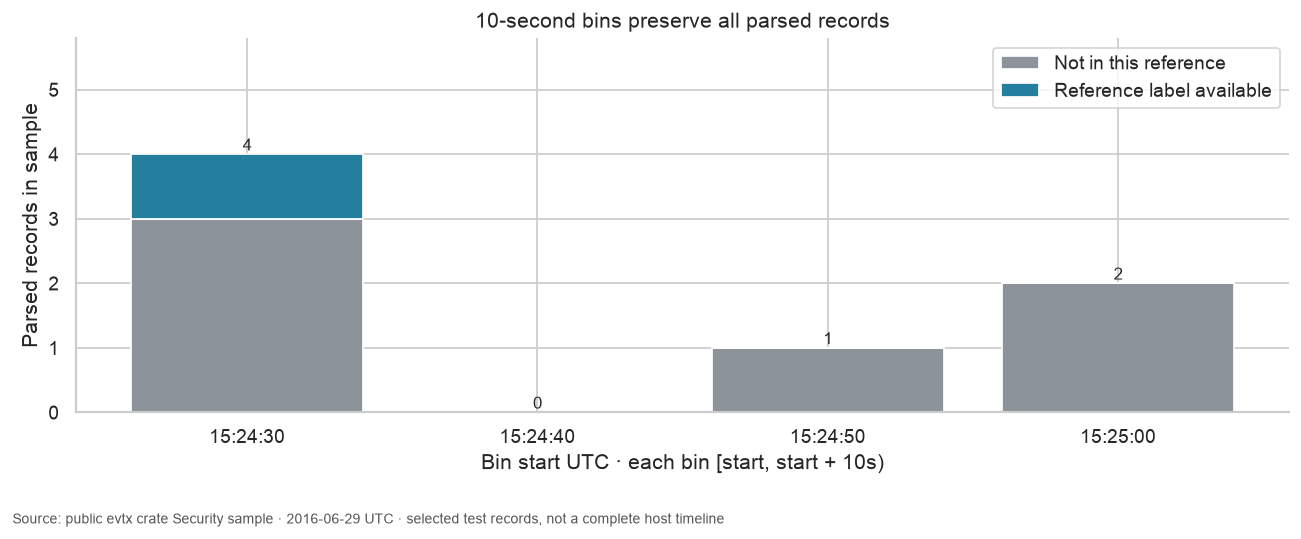

In [14]:
display(bins)
assert bins.parsed_records.sum()==len(timeline)
assert bins.labeled_records.sum()==known
assert (bins.labeled_records+bins.unlabeled_records).equals(bins.parsed_records)
assert (bins.bin_end_utc-bins.bin_start_utc).dt.total_seconds().eq(BIN_SECONDS).all()
assert all(((timeline.record_time_utc>=r.bin_start_utc)&(timeline.record_time_utc<r.bin_end_utc)).sum()==r.parsed_records for r in bins.itertuples())
prose(f"At **{BIN_SECONDS}-second width**, the display has **{len(bins)} bins** and a largest bin of **{int(bins.parsed_records.max())} records**. "
      f"The total is still **{int(bins.parsed_records.sum())}**, with **{int(bins.labeled_records.sum())}** reference-labeled records. Bin width changes aggregation, not the underlying evidence.")
fig,ax=plt.subplots(figsize=(10.5,4.4))
labels=bins.bin_start_utc.dt.strftime("%H:%M:%S")
ax.bar(labels,bins.unlabeled_records,color="#8c939a",label="Not in this reference")
ax.bar(labels,bins.labeled_records,bottom=bins.unlabeled_records,color="#247f9e",label="Reference label available")
for i,r in enumerate(bins.itertuples()):ax.text(i,r.parsed_records+.06,str(r.parsed_records),ha="center",fontsize=10)
ax.set(xlabel=f"Bin start UTC · each bin [start, start + {BIN_SECONDS}s)",ylabel="Parsed records in sample",title=f"{BIN_SECONDS}-second bins preserve all parsed records",ylim=(0,max(1,int(bins.parsed_records.max()))*1.45))
ax.yaxis.set_major_locator(MaxNLocator(integer=True));ax.legend(loc="upper right");finish(fig)

## One change to test

Change only **`BIN_SECONDS` from `10` to `30`** in a separate executed copy. Compare the fixture hash, parsed count, individual-event chart and reference coverage: those must stay fixed. The bin table and largest-bin count can change. Restore **10** afterward.

The sample is too small and deliberately selected to support a claim about host behavior. Parser success, a continuous sequence of record IDs and agreement between two parser functions do not prove authenticity, absence of corruption or full collection. The worker caps input at 256 MiB and output at 5,000,000 records and skips per-record parse errors; keep those limits in mind when applying the same SQL to a different authorized collection.

In [15]:
con.execute("DETACH evtx")
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and provenance](README.md)